# SDG 11 — Sustainable Cities and Communities
## Analysis of Air Quality in Indian Cities

---

| Item | Detail |
|---|---|
| **Subject** | Data Exploration and Visualization (23CS5PCDEV) |
| **College** | B.M.S. College of Engineering, Bangalore |
| **Dataset** | Indian Cities Air Quality — city_day.csv (CPCB) |
| **SDG Goal** | SDG 11: Sustainable Cities & Communities |
| **Target** | 11.6 — Reduce the environmental impact of cities |

---

## Workflow

The notebook uses the same preprocessing functions as the command-line pipeline. It inspects the raw data, shows each cleaning stage, explores AQI, checks sensitivity to data coverage and quality, and writes 12 PNG charts to `outputs/graphs/`. Run `python run_all.py` to also export the processed datasets and statistical tables.

---
## Introduction and Research Questions

### SDG 11 Context

**UN Sustainable Development Goal 11** aims to make cities inclusive, safe, resilient, and sustainable by 2030.  
**Target 11.6** specifically calls for reducing the per capita environmental impact of cities, with particular attention to air quality and municipal waste management.

This study uses reported daily city AQI as an exploratory measure. The official SDG indicator 11.6.2 tracks annual mean particulate matter concentrations weighted by population. See the [UN indicator metadata](https://unstats.un.org/sdgs/metadata/files/Metadata-11-06-02.pdf).

### Research Questions

This analysis answers the following specific questions:

1. Which Indian city has the **highest average AQI** (most polluted)?
2. Which city has the **lowest average AQI** (least polluted)?
3. How has AQI **changed year by year** from 2015 to 2020?
4. Which **months or seasons** are most polluted?
5. What is the **distribution of AQI categories** across all records?
6. Which **pollutants correlate most strongly** with AQI?
7. What is the **relationship between PM2.5 and PM10**?
8. How do **pollutant levels vary across cities**?

## Setup

In [30]:
from pathlib import Path
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "src" / "dfmodif.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Start Jupyter from the project directory or its notebooks subdirectory.")
sys.path.insert(0, str(PROJECT_ROOT))

from src.analysis import (
    KEY_COLUMNS, MONTH_ORDER, aqi_summary,
    city_aqi_category_profile, comparable_period, numeric_profile,
    selected_relationships, sensitivity_checks,
)
from src.dfmodif import AQI_CATEGORIES, POLLUTANTS, RAW_PATH, clean_city_days, prepare_city_days, quality_report

GRAPH_DIR = PROJECT_ROOT / "outputs" / "graphs"
GRAPH_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 150, "savefig.bbox": "tight"})

# 1 Dataset Overview

The source is [Air Quality Data in India](https://www.kaggle.com/datasets/rohanrao/air-quality-data-in-india). Each record describes a city and calendar day. AQI is a reported index. The city-day file does not identify monitoring stations.

## Raw preview and variable types

In [31]:
df_raw = pd.read_csv(RAW_PATH)
print(f"{df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
df_raw.info()
print("First five rows")
display(df_raw.head())
print("Last five rows")
display(df_raw.tail())
display(df_raw.describe())

29,531 rows × 16 columns
<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  str    
 1   Date        29531 non-null  str    
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  str    
dtypes: float64(13), str(3)
memory usage: 3.6 MB
First five rows


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


Last five rows


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
29526,Visakhapatnam,2020-06-27,15.02,50.94,7.68,25.06,19.54,12.47,0.47,8.55,23.30,2.24,12.07,0.73,41.0,Good
29527,Visakhapatnam,2020-06-28,24.38,74.09,3.42,26.06,16.53,11.99,0.52,12.72,30.14,0.74,2.21,0.38,70.0,Satisfactory
29528,Visakhapatnam,2020-06-29,22.91,65.73,3.45,29.53,18.33,10.71,0.48,8.42,30.96,0.01,0.01,0.00,68.0,Satisfactory
29529,Visakhapatnam,2020-06-30,16.64,49.97,4.05,29.26,18.80,10.03,0.52,9.84,28.30,0.00,0.00,0.00,54.0,Satisfactory
29530,Visakhapatnam,2020-07-01,15.00,66.00,0.40,26.85,14.05,5.20,0.59,2.10,17.05,NaN,NaN,NaN,50.0,Good


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,24933.000000,18391.000000,25949.000000,25946.000000,25346.000000,19203.000000,27472.000000,25677.000000,25509.000000,23908.000000,21490.000000,11422.000000,24850.000000
mean,67.450578,118.127103,17.574730,28.560659,32.309123,23.483476,2.248598,14.531977,34.491430,3.280840,8.700972,3.070128,166.463581
std,64.661449,90.605110,22.785846,24.474746,31.646011,25.684275,6.962884,18.133775,21.694928,15.811136,19.969164,6.323247,140.696585
min,0.040000,0.010000,0.020000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000,13.000000
25%,28.820000,56.255000,5.630000,11.750000,12.820000,8.580000,0.510000,5.670000,18.860000,0.120000,0.600000,0.140000,81.000000
50%,48.570000,95.680000,9.890000,21.690000,23.520000,15.850000,0.890000,9.160000,30.840000,1.070000,2.970000,0.980000,118.000000
75%,80.590000,149.745000,19.950000,37.620000,40.127500,30.020000,1.450000,15.220000,45.570000,3.080000,9.150000,3.350000,208.000000
max,949.990000,1000.000000,390.680000,362.210000,467.630000,352.890000,175.810000,193.860000,257.730000,455.030000,454.850000,170.370000,2049.000000


| Field | Type and meaning |
|---|---|
| City | Nominal city name |
| Date | Calendar date, converted from source text to datetime |
| AQI | Numeric reported air quality index |
| AQI_Bucket | Ordinal reported category from Good through Severe |
| PM2.5, PM10 | Numeric particulate concentrations at two particle size cutoffs |
| NO, NO2, NOx | Numeric nitric oxide, nitrogen dioxide, and total nitrogen oxides |
| NH3, CO, SO2, O3 | Numeric ammonia, carbon monoxide, sulfur dioxide, and ozone |
| Benzene, Toluene, Xylene | Numeric concentrations of individually named volatile organic compounds |

The derived Year and Month support aggregation. PM2.5_Severity is an ordinal concentration band separate from the reported AQI category.

In [32]:
raw_columns = pd.DataFrame({
    "Missing": df_raw.isna().sum(),
    "Missing (%)": df_raw.isna().mean().mul(100).round(2),
    "Distinct observed": df_raw.nunique(),
})
display(raw_columns)
display(df_raw["AQI_Bucket"].value_counts().reindex(AQI_CATEGORIES, fill_value=0))
print("Most frequent observed city:", ", ".join(df_raw["City"].mode()))
print("Most frequent reported AQI category:", ", ".join(df_raw["AQI_Bucket"].mode()))

,Missing,Missing (%),Distinct observed
City,0,0.00,26
Date,0,0.00,2009
PM2.5,4598,15.57,11716
PM10,11140,37.72,12571
NO,3582,12.13,5776
NO2,3585,12.14,7404
NOx,4185,14.17,8156
NH3,10328,34.97,5922
CO,2059,6.97,1779
SO2,3854,13.05,4761


AQI_Bucket
Good            1341
Satisfactory    8224
Moderate        8829
Poor            2781
Very Poor       2337
Severe          1338
Name: count, dtype: int64

Most frequent observed city: Ahmedabad, Bengaluru, Chennai, Delhi, Lucknow, Mumbai
Most frequent reported AQI category: Moderate


# 2 Data Quality and Cleaning

The missingness bars compare fields on the x-axis and percentages of source records on the y-axis. The largest gap is Xylene.

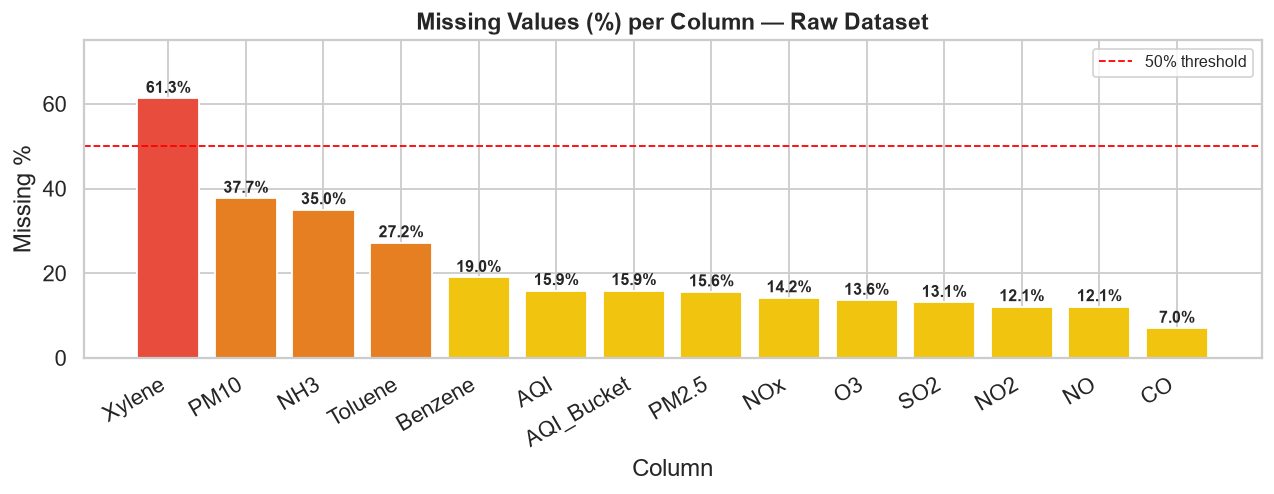

Chart saved → outputs/graphs/00_raw_missing_values.png


In [33]:
# Missing values in the raw dataset
raw_missing     = df_raw.isnull().sum()
raw_missing_pct = (raw_missing / len(df_raw) * 100).round(1)

missing_df = pd.DataFrame({
    'Missing Count': raw_missing,
    'Missing %'    : raw_missing_pct
})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing %', ascending=False)



# Bar chart of missing values
fig, ax = plt.subplots(figsize=(10, 4))
colors = ['#e74c3c' if p > 50 else '#e67e22' if p > 25 else '#f1c40f'
          for p in missing_df['Missing %']]
ax.bar(missing_df.index, missing_df['Missing %'], color=colors, edgecolor='white')
for i, (col, row) in enumerate(missing_df.iterrows()):
    ax.text(i, row['Missing %'] + 0.5, f"{row['Missing %']}%",
            ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.axhline(50, color='red', linestyle='--', linewidth=1, label='50% threshold')
ax.set_title('Missing Values (%) per Column — Raw Dataset', fontsize=13, fontweight='bold')
ax.set_xlabel('Column')
ax.set_ylabel('Missing %')
ax.set_ylim(0, 75)
ax.legend(fontsize=9)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, '00_raw_missing_values.png'))
plt.show()
print('Chart saved → outputs/graphs/00_raw_missing_values.png')

## Format and duplicate checks

Standardize city whitespace and dates. Exact duplicate rows represent repeated copies. Conflicting records with the same city-day key need review before aggregation. Repeated days for a city with different dates are valid observations.

In [34]:
print("Exact repeated raw rows:", df_raw.duplicated().sum())
print("City labels with surrounding whitespace:", df_raw["City"].ne(df_raw["City"].str.strip()).sum())
print("Unexpected reported AQI labels:", sorted(set(df_raw["AQI_Bucket"].dropna()) - set(AQI_CATEGORIES)))
prepared = prepare_city_days(df_raw)
print("Duplicate normalized city-day keys:", prepared.duplicated(["City", "Date"]).sum())
print(f"Exact duplicates removed: {len(df_raw) - len(prepared):,}")
print(f"Xylene missing: {df_raw['Xylene'].isna().mean():.1%}")
display(prepared[['City', 'Date']].head())

Exact repeated raw rows: 0
City labels with surrounding whitespace: 0
Unexpected reported AQI labels: []
Duplicate normalized city-day keys: 0
Exact duplicates removed: 0
Xylene missing: 61.3%


,City,Date
0,Ahmedabad,2015-01-01
1,Ahmedabad,2015-01-02
2,Ahmedabad,2015-01-03
3,Ahmedabad,2015-01-04
4,Ahmedabad,2015-01-05


# 3 Data Cleaning Justifications

Xylene is dropped because 61.3% of the source values are missing. Within-city forward fill and backward fill use nearby observations in the ordered series. These fills may span long gaps. A column median handles residual missing values and limits the influence of extreme concentrations on that fallback. AQI and its category stay as reported, so we exclude rows missing either field. The project preserves the original CSV.

In [35]:
df_cleaned = clean_city_days(prepared)
missing_pollutants = pd.DataFrame({
    "Before cleaning": prepared[POLLUTANTS].isna().sum(),
    "In analysis dataset": df_cleaned[POLLUTANTS].isna().sum(),
})
display(missing_pollutants)
print(f"Rows excluded for missing AQI or category: {len(prepared) - len(df_cleaned):,}")
display(df_cleaned[['Date', 'Year', 'Month', 'PM2.5_Severity']].head())

,Before cleaning,In analysis dataset
PM2.5,4598,0
PM10,11140,0
NO,3582,0
NO2,3585,0
NOx,4185,0
NH3,10328,0
CO,2059,0
SO2,3854,0
O3,4022,0
Benzene,5623,0


Rows excluded for missing AQI or category: 4,681


,Date,Year,Month,PM2.5_Severity
0,2015-01-29,2015,January,Moderately Polluted
1,2015-01-30,2015,January,Moderately Polluted
2,2015-01-31,2015,January,Poor
3,2015-02-01,2015,February,Very Poor
4,2015-02-02,2015,February,Very Poor


## Quality flags and outliers

AQI values above 500 and PM10 below PM2.5 warrant source-level review. The IQR diagnostic in the numeric profile flags values outside the quartile fences as statistical extremes. A flag identifies a record to examine. Its origin or validity cannot be determined from this file alone.

In [36]:
display(quality_report(prepared, df_cleaned))

,Issue,Count,Action
0,Negative PM2.5,0,Checked
1,Negative PM10,0,Checked
2,Negative NO,0,Checked
3,Negative NO2,0,Checked
4,Negative NOx,0,Checked
5,Negative NH3,0,Checked
6,Negative CO,0,Checked
7,Negative SO2,0,Checked
8,Negative O3,0,Checked
9,Negative Benzene,0,Checked


## Before and after cleaning

In [37]:
display(pd.DataFrame(
    {
        "Raw": [len(df_raw), len(df_raw.columns), df_raw.duplicated().sum(), df_raw.isna().sum().sum()],
        "Cleaned": [len(df_cleaned), len(df_cleaned.columns), df_cleaned.duplicated().sum(),
                    df_cleaned.isna().sum().sum()],
    },
    index=["Rows", "Columns", "Exact duplicates", "Missing cells"],
))

,Raw,Cleaned
Rows,29531,24850
Columns,16,18
Exact duplicates,0,0
Missing cells,88488,0


# 4 Descriptive Statistics

The cleaned profile includes all retained concentration fields and AQI. The raw profile includes Xylene and gives a measured baseline.

In [38]:
raw_numeric = numeric_profile(df_raw)
cleaned_numeric = numeric_profile(df_cleaned[[*POLLUTANTS, "AQI"]])
display(raw_numeric.loc[:, ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]])
display(cleaned_numeric.loc[:, ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]])

,count,mean,std,min,25%,50%,75%,max
Variable,,,,,,,,
PM2.5,24933.0,67.451,64.661,0.04,28.820,48.57,80.590,949.99
PM10,18391.0,118.127,90.605,0.01,56.255,95.68,149.745,1000.00
NO,25949.0,17.575,22.786,0.02,5.630,9.89,19.950,390.68
NO2,25946.0,28.561,24.475,0.01,11.750,21.69,37.620,362.21
NOx,25346.0,32.309,31.646,0.00,12.820,23.52,40.128,467.63
NH3,19203.0,23.483,25.684,0.01,8.580,15.85,30.020,352.89
CO,27472.0,2.249,6.963,0.00,0.510,0.89,1.450,175.81
SO2,25677.0,14.532,18.134,0.01,5.670,9.16,15.220,193.86
O3,25509.0,34.491,21.695,0.01,18.860,30.84,45.570,257.73


,count,mean,std,min,25%,50%,75%,max
Variable,,,,,,,,
PM2.5,24850.0,68.881,64.843,0.04,28.900,48.850,82.218,914.94
PM10,24850.0,121.749,90.565,0.03,58.320,97.150,153.968,917.08
NO,24850.0,17.757,22.892,0.03,5.630,9.930,20.040,390.68
NO2,24850.0,28.669,24.629,0.01,11.710,21.845,37.938,362.21
NOx,24850.0,31.728,29.985,0.00,13.400,23.640,39.078,378.24
NH3,24850.0,26.611,27.485,0.01,9.030,17.000,38.770,352.89
CO,24850.0,2.321,7.016,0.00,0.580,0.930,1.470,175.81
SO2,24850.0,14.496,17.831,0.01,5.652,9.190,15.278,186.08
O3,24850.0,35.041,22.083,0.01,19.282,31.120,45.928,257.73


# 5 Measures of Central Tendency

AQI has a mean of 166.5 and a median of 118. The gap is descriptive evidence of the influence of high values. The median is a useful typical city-day summary. Moderate is the most common reported AQI category. Exact modes provide little insight for continuous concentrations recorded at finite precision. Compare pollutant means within a common unit and use AQI separately.

For comparable particulate units, PM10 has the higher mean (121.75 µg/m³) and PM2.5 the lower mean (68.88 µg/m³).

In [39]:
# Detailed AQI statistics
aqi = df_cleaned['AQI']
print('AQI — Key Statistics')
print(f'  Mean              : {aqi.mean():.1f}')
print(f'  Median            : {aqi.median():.1f}')
print(f'  Std Deviation     : {aqi.std():.1f}')
print(f'  Min               : {aqi.min():.0f}')
print(f'  Max               : {aqi.max():.0f}')
print(f'  25th Percentile   : {aqi.quantile(0.25):.1f}')
print(f'  75th Percentile   : {aqi.quantile(0.75):.1f}')
print(f'  Skewness          : {aqi.skew():.2f}  (right-skewed = long tail of high values)')
print(f'  Records > 300     : {(aqi > 300).sum():,}  ({(aqi > 300).mean()*100:.1f}%)')
print(f'  Records > 500     : {(aqi > 500).sum():,}  ({(aqi > 500).mean()*100:.1f}%)')

AQI — Key Statistics
  Mean              : 166.5
  Median            : 118.0
  Std Deviation     : 140.7
  Min               : 13
  Max               : 2049
  25th Percentile   : 81.0
  75th Percentile   : 208.0
  Skewness          : 3.40  (right-skewed = long tail of high values)
  Records > 300     : 3,675  (14.8%)
  Records > 500     : 543  (2.2%)


# 6 Measures of Dispersion

IQR measures the middle half of each distribution. Standard deviation and range respond more to the extreme tail. Variance is in squared units. CV compares relative spread across positive-mean concentrations, including measurements in different units, though means close to zero can inflate it. IQR flags are review indicators and remain in the baseline.

PM10 has the larger absolute IQR (95.65 versus 53.32 µg/m³), while PM2.5 has the larger CV (94.14% versus 74.39%). Benzene has the highest concentration CV (478.42%) and strong right skew. AQI has IQR 127 (81 to 208) and skewness 3.397, consistent with the upper tail shown in the histogram.

In [40]:
display(cleaned_numeric[["Range", "Variance", "std", "IQR", "CV_pct", "Skewness", "Outside_IQR_Fences"]])
print("Highest relative variation among retained concentrations:",
      cleaned_numeric["CV_pct"].idxmax())
print("AQI median and IQR:", cleaned_numeric.loc["AQI", ["50%", "IQR"]].to_dict())

,Range,Variance,std,IQR,CV_pct,Skewness,Outside_IQR_Fences
Variable,,,,,,,
PM2.5,914.90,4204.596,64.843,53.318,94.138,2.816,2140
PM10,917.05,8201.948,90.565,95.648,74.386,1.963,1537
NO,390.65,524.061,22.892,14.410,128.921,3.633,2402
NO2,362.20,606.600,24.629,26.228,85.909,2.447,1098
NOx,378.24,899.125,29.985,25.678,94.508,2.509,1795
NH3,352.88,755.403,27.485,29.740,103.282,3.278,904
CO,175.81,49.230,7.016,0.890,302.280,8.700,2315
SO2,186.07,317.929,17.831,9.625,123.004,3.897,2462
O3,257.72,487.658,22.083,26.645,63.020,1.380,755


Highest relative variation among retained concentrations: Benzene
AQI median and IQR: {'50%': 118.0, 'IQR': 127.0}


# 7 Univariate Analysis

Examine one field at a time. The AQI histogram shows the distribution's shape, the category bars show how common each reported AQI level was, and the pollutant box plots show how the middle half of the concentrations compares with each upper tail.

## AQI distribution

**What it shows:** How AQI values are distributed across all 24,850 city-day records.  
The vertical dashed lines mark the official category boundaries.

A histogram shows distribution shape. The x-axis is AQI and the y-axis is city-day frequency. The right tail helps explain why the mean exceeds the median.

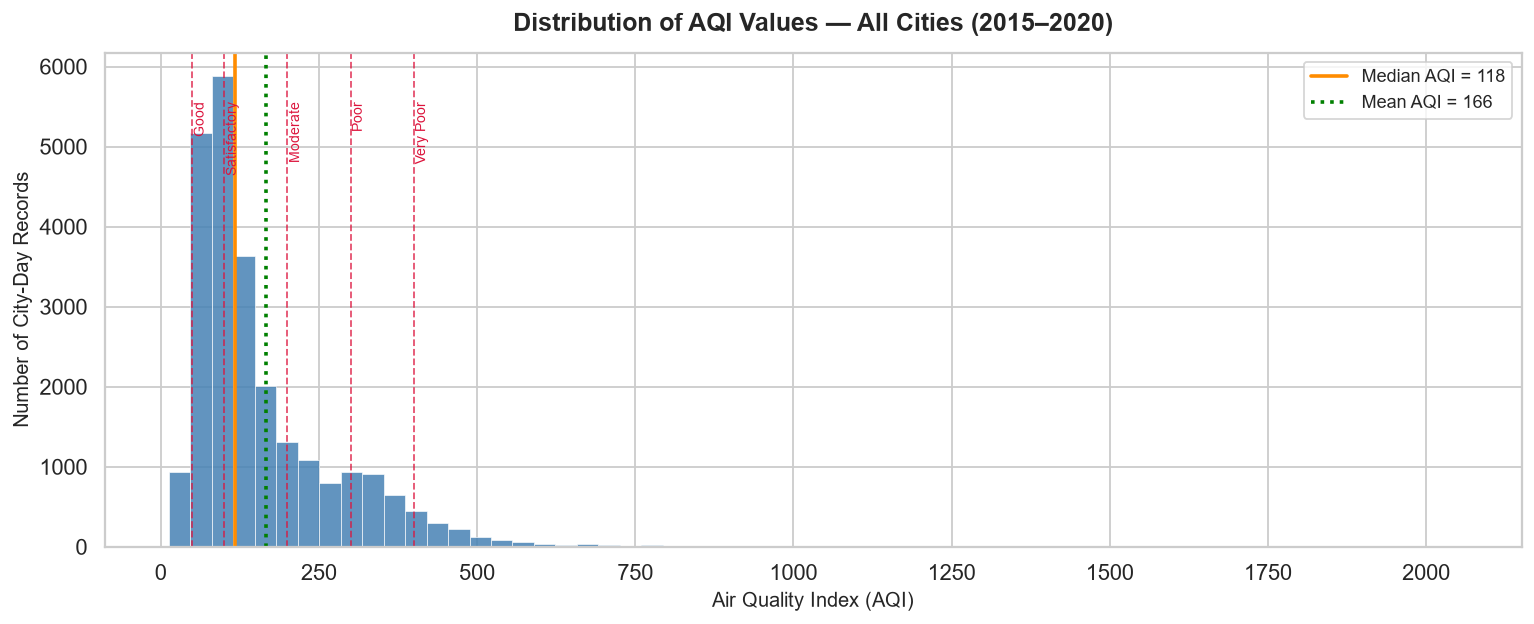

Mean: 166.5 | Median: 118 | Skewness: 3.40
The distribution is right-skewed, with a tail of reported values above 500.


In [41]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.hist(df_cleaned['AQI'], bins=60, color='steelblue', edgecolor='white', linewidth=0.4, alpha=0.85)

boundaries = {50: 'Good', 100: 'Satisfactory', 200: 'Moderate', 300: 'Poor', 400: 'Very Poor'}
for xval, label in boundaries.items():
    ax.axvline(xval, color='crimson', linestyle='--', linewidth=1.0, alpha=0.75)
    ax.text(xval + 2, ax.get_ylim()[1] * 0.90, label,
            fontsize=7.5, color='crimson', rotation=90, va='top')

median_aqi = df_cleaned['AQI'].median()
mean_aqi   = df_cleaned['AQI'].mean()
ax.axvline(median_aqi, color='darkorange', linestyle='-',  linewidth=2, label=f'Median AQI = {median_aqi:.0f}')
ax.axvline(mean_aqi,   color='green',      linestyle=':', linewidth=2, label=f'Mean AQI = {mean_aqi:.0f}')

ax.set_title('Distribution of AQI Values — All Cities (2015–2020)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Air Quality Index (AQI)', fontsize=11)
ax.set_ylabel('Number of City-Day Records', fontsize=11)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'aqi_distribution.png'))
plt.show()

print(f'Mean: {mean_aqi:.1f} | Median: {median_aqi:.0f} | Skewness: {df_cleaned["AQI"].skew():.2f}')
print('The distribution is right-skewed, with a tail of reported values above 500.')

## Reported AQI categories

**What it shows:** Count of city-day records per official CPCB AQI category.

Research question 5 compares the reported AQI categories.

A bar chart compares counts across ordered reported categories. The x-axis is AQI category and the y-axis is city-day count. Moderate has the most observations.

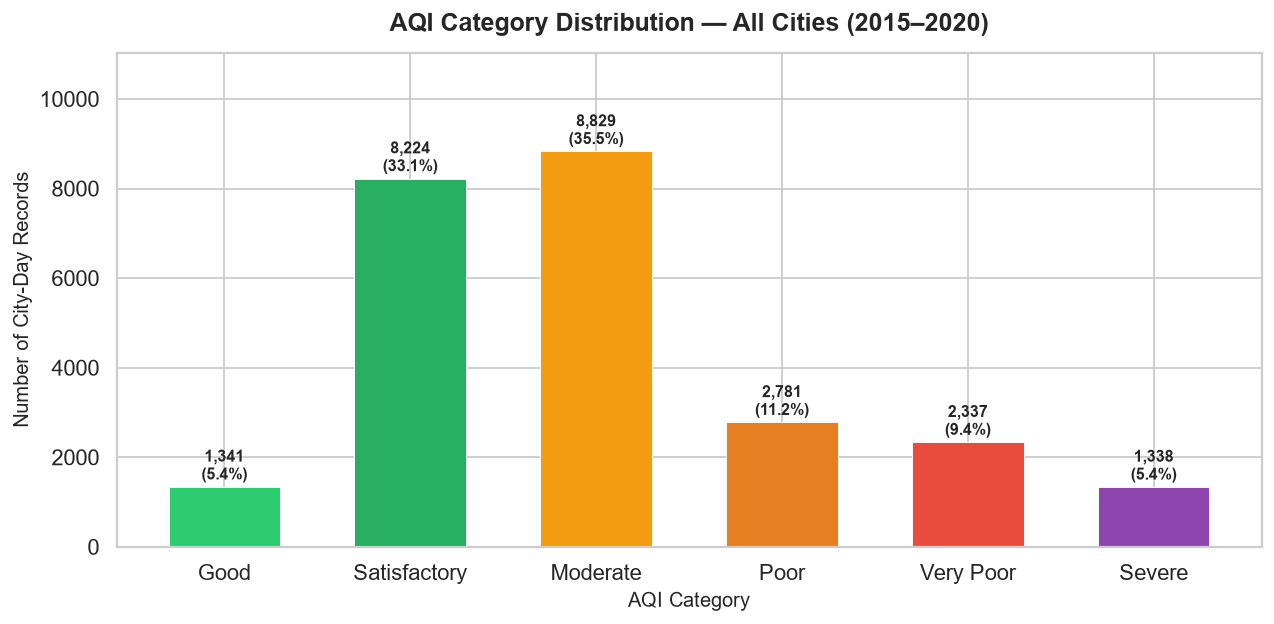

Days with Poor/Very Poor/Severe AQI: 6,456 (26.0%)


In [42]:
cat_order  = AQI_CATEGORIES
cat_colors = ['#2ecc71', '#27ae60', '#f39c12', '#e67e22', '#e74c3c', '#8e44ad']
counts = df_cleaned['AQI_Bucket'].value_counts().reindex(cat_order, fill_value=0)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(counts.index, counts.values, color=cat_colors, edgecolor='white', linewidth=0.5, width=0.6)

for bar in bars:
    h   = bar.get_height()
    pct = h / len(df_cleaned) * 100
    ax.text(bar.get_x() + bar.get_width() / 2, h + 60,
            f'{int(h):,}\n({pct:.1f}%)',
            ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_title('AQI Category Distribution — All Cities (2015–2020)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('AQI Category', fontsize=11)
ax.set_ylabel('Number of City-Day Records', fontsize=11)
ax.set_ylim(0, counts.max() * 1.25)
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'aqi_category_distribution.png'))
plt.show()

poor_days = counts[['Poor','Very Poor','Severe']].sum()
print(f'Days with Poor/Very Poor/Severe AQI: {poor_days:,} ({poor_days/len(df_cleaned)*100:.1f}%)')

## Pollutant distributions

Box plots compare medians, IQRs and upper tails on separate scales. The vertical axes show concentrations for the respective pollutant. Horizontal position separates panels and does not encode magnitude.

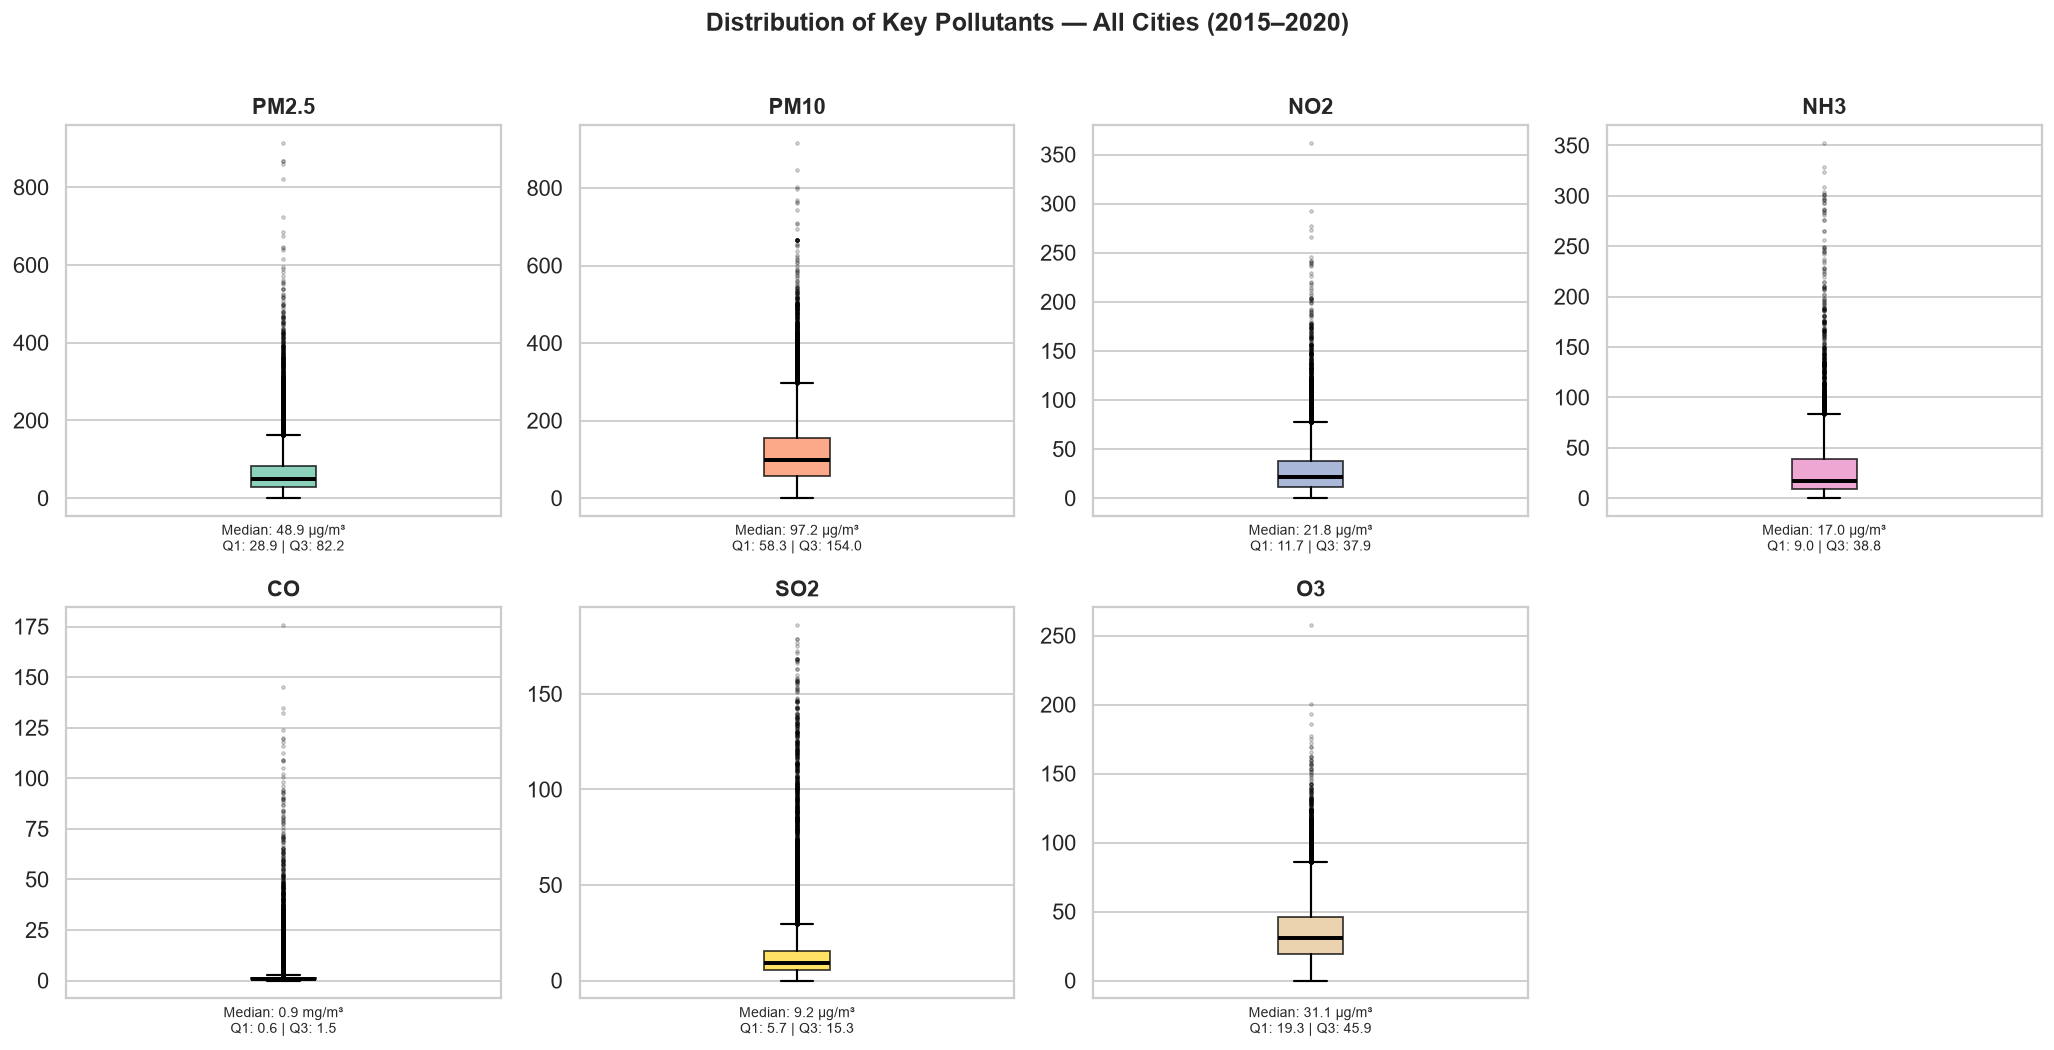

In [43]:
pollutants = ['PM2.5', 'PM10', 'NO2', 'NH3', 'CO', 'SO2', 'O3']
palette    = sns.color_palette('Set2', len(pollutants))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, (pol, color) in enumerate(zip(pollutants, palette)):
    axes[i].boxplot(
        df_cleaned[pol].dropna(),
        patch_artist=True,
        boxprops    =dict(facecolor=color, alpha=0.75),
        medianprops =dict(color='black', linewidth=2.2),
        whiskerprops=dict(linewidth=1.2),
        capprops    =dict(linewidth=1.2),
        flierprops  =dict(marker='o', markersize=1.5, alpha=0.25, color=color)
    )
    median_val = df_cleaned[pol].median()
    q1  = df_cleaned[pol].quantile(0.25)
    q3  = df_cleaned[pol].quantile(0.75)
    unit = 'mg/m³' if pol == 'CO' else 'µg/m³'
    axes[i].set_title(pol, fontweight='bold', fontsize=12)
    axes[i].set_xlabel(f'Median: {median_val:.1f} {unit}\nQ1: {q1:.1f} | Q3: {q3:.1f}', fontsize=8)
    axes[i].set_xticks([])

axes[-1].set_visible(False)
fig.suptitle('Distribution of Key Pollutants — All Cities (2015–2020)', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'pollutant_boxplots.png'))
plt.show()


**What stands out.** Median AQI was 118, below the mean of 166.5, and the histogram shows the upper tail that pulls the mean upward. Moderate was the most frequent category (35.5%). The PM10 box spans a wider concentration interval than the PM2.5 box, with IQRs of 95.65 and 53.32 µg/m³. Use each pollutant panel's own scale, especially for CO, which is in mg/m³. The numeric profiles in Section 4 cover the full set of fields.

# 8 Relationship Analysis

Compare city with mean AQI and examine whether the city rankings depend on extreme readings. Sections 9 and 10 compare calendar groups and category shares. Section 11 shows the pollutant associations.

In [44]:
# Research Question 1 & 2: Most and least polluted cities
city_avg = df_cleaned.groupby('City')['AQI'].mean().sort_values(ascending=False).round(1)

print('Top 5 most polluted cities (highest mean AQI):')
for city, aqi_val in city_avg.head(5).items():
    print(f'  {city:<20s}: {aqi_val}')

print('\nTop 5 least polluted cities (lowest mean AQI):')
for city, aqi_val in city_avg.tail(5).items():
    print(f'  {city:<20s}: {aqi_val}')

Top 5 most polluted cities (highest mean AQI):
  Ahmedabad           : 452.1
  Delhi               : 259.5
  Patna               : 240.8
  Gurugram            : 225.1
  Lucknow             : 218.0

Top 5 least polluted cities (lowest mean AQI):
  Ernakulam           : 92.4
  Thiruvananthapuram  : 75.9
  Coimbatore          : 73.0
  Shillong            : 53.8
  Aizawl              : 34.8


In [45]:
# Research Question 7 and sensitivity to extreme AQI
pm_correlation, city_sensitivity = sensitivity_checks(prepared, df_cleaned)
display(pm_correlation)
display(city_sensitivity.head())
print("Ahmedabad after excluding AQI above 500:", city_sensitivity.loc["Ahmedabad", "Mean_AQI_Up_To_500"])

,Records,Pearson_r
Input,,
Measured pairs,17146,0.853
After imputation,24850,0.594


,Mean_AQI,Records,Mean_AQI_Up_To_500,Records_Up_To_500
City,,,,
Ahmedabad,452.1,1334,291.7,922
Delhi,259.5,1999,252.1,1951
Patna,240.8,1459,235.6,1434
Gurugram,225.1,1453,219.4,1431
Lucknow,218.0,1893,215.2,1878


Ahmedabad after excluding AQI above 500: 291.7


# 9 Relevant Grouping and Aggregation

City means compare available city-days. Calendar month means pool available years. The year comparison also examines the same January through June window with a minimum 80% coverage requirement in every study year. This controls the calendar window and which cities enter that comparison. Only Delhi meets the rule.

In [46]:
# City-wise AQI statistics
display(aqi_summary(df_cleaned, "City").sort_values("Mean", ascending=False))

,Mean,Median,StdDev,Records
City,,,,
Ahmedabad,452.1,384.5,311.7,1334
Delhi,259.5,257.0,119.5,1999
Patna,240.8,215.0,122.3,1459
Gurugram,225.1,208.0,119.9,1453
Lucknow,218.0,198.0,117.0,1893
Talcher,172.9,128.5,104.9,698
Jorapokhar,159.3,133.0,84.7,771
Brajrajnagar,150.3,122.0,70.4,713
Kolkata,140.6,94.0,104.5,754


In [47]:
# Research Question 3: Compare pooled and comparable-period AQI
year_summary = aqi_summary(df_cleaned, "Year")
year_summary["Cities"] = df_cleaned.groupby("Year")["City"].nunique()
display(year_summary)

panel, panel_cities = comparable_period(df_cleaned)
print("Cities with at least 80% January–June coverage every year:", ", ".join(panel_cities) or "none")
display(panel)

,Mean,Median,StdDev,Records,Cities
Year,,,,,
2015,212.5,175.0,133.1,1827,7
2016,197.2,149.0,130.5,2573,9
2017,181.5,129.0,141.4,3234,15
2018,182.7,124.0,171.5,5724,18
2019,156.5,109.0,135.8,7071,23
2020,113.5,93.0,83.5,4421,26


Cities with at least 80% January–June coverage every year: Delhi


,Mean_AQI,Records,Cities
Year,,,
2015,306.3,181,1
2016,298.0,182,1
2017,293.6,180,1
2018,262.9,181,1
2019,245.9,181,1
2020,182.1,182,1


In [48]:
# Research Question 4: Pooled monthly AQI and record counts
display(aqi_summary(df_cleaned, "Month").reindex(MONTH_ORDER))

,Mean,Median,StdDev,Records
Month,,,,
January,231.7,183.0,160.7,2141
February,202.9,149.5,164.9,2078
March,164.7,124.0,138.1,2327
April,143.4,111.0,115.1,2295
May,135.5,111.0,90.6,2447
June,120.2,96.0,92.7,2344
July,111.9,86.0,100.9,1836
August,113.6,85.0,99.3,1776
September,115.2,88.0,94.1,1757


# 10 Relevant Cross Tabulation

Do high average AQI cities also record Poor or worse AQI more often? A row-normalized City × AQI_Bucket cross-tab answers a frequency question that a mean cannot. Use the last full calendar year (2019) and include cities with at least 300 reported days for comparable calendar coverage. Each row describes shares among that city's recorded days.

A pivot table would repeat the group summaries or the category cross-tab. We use the cross-tab for composition, groupby for AQI means, and skip a categorical test that would treat serially dependent days as independent.

In [49]:
category_profile = city_aqi_category_profile(df_cleaned)
display(category_profile)
print("Cities eligible in 2019:", len(category_profile))

AQI_Bucket,Good,Satisfactory,Moderate,Poor,Very Poor,Severe,Poor_or_Worse_pct,Records
City,,,,,,,,
Ahmedabad,0.00,0.00,4.83,10.51,21.02,63.64,95.17,352
Delhi,0.00,11.78,35.07,27.12,16.16,9.86,53.15,365
Lucknow,0.00,20.55,33.70,23.56,20.00,2.19,45.75,365
Patna,0.00,15.04,40.67,13.37,21.73,9.19,44.29,359
Gurugram,2.75,21.70,33.24,22.53,15.93,3.85,42.31,364
Talcher,0.66,28.71,42.57,12.87,11.88,3.30,28.05,303
Kolkata,14.52,36.99,21.37,17.26,7.40,2.47,27.12,365
Jorapokhar,1.98,23.43,49.50,18.81,3.96,2.31,25.08,303
Brajrajnagar,0.62,19.25,59.01,17.70,3.42,0.00,21.12,322


Cities eligible in 2019: 19


# 11 Correlation and Statistical Analysis

Pearson r summarizes linear association. Spearman measures how consistently values rise or fall together after being converted to ranks. The table compares the two coefficients on measured pairs and includes Pearson r after filling gaps. Read the sample count alongside each coefficient because measurement coverage differs by pair.

## Selected measured and filled relationships

In [50]:
relationships = selected_relationships(prepared, df_cleaned)
display(relationships)

,X,Y,Measured_Pairs,Measured_Pearson,Measured_Spearman,Cleaned_Pearson
0,PM2.5,PM10,17146,0.853,0.881,0.594
1,PM10,AQI,17764,0.803,0.871,0.514
2,PM2.5,AQI,24172,0.659,0.846,0.635
3,CO,AQI,24405,0.683,0.549,0.678
4,NO,NOx,22811,0.801,0.764,0.764
5,Benzene,Toluene,18672,0.764,0.754,0.671
6,NH3,SO2,17958,-0.028,0.097,-0.058


PM2.5 and PM10 are closely related in measured pairs (Pearson 0.853). PM10 and AQI also move together (0.803), with an even stronger rank relationship (0.871). For PM2.5 and AQI, the larger gap between Pearson (0.659) and rank correlation (0.846) shows that the monotonic relationship is stronger than the linear one in this sample. CO and AQI show the reverse pattern (0.683 and 0.549), which shows stronger linear than rank association here. Differences between the coefficients alone cannot identify which observations drive the gap.

NO and NOx share a chemical component and are strongly associated (0.801), so they may carry overlapping information in a future model. Benzene and toluene also move together (0.764). NH3 and SO2 provide a useful counterexample. Their measured Pearson coefficient is −0.028 and rank coefficient is 0.097, so neither supports a meaningful inverse relationship. Pair counts differ because both values must be present. Comparing measured and filled coefficients changes the sample as well as the missing-value treatment.

AQI is derived from pollution measurements. Pollutants measured on the same date are potentially useful for estimating reported AQI, but would constitute leakage for a forecast if they are unavailable at prediction time. No prediction model is fitted here.

## Cleaned data correlation heatmap

A heatmap organizes many related coefficients. Both axes list pollutants and AQI. Color and labels encode Pearson r. CO and PM2.5 are most associated with AQI in this cleaned matrix.

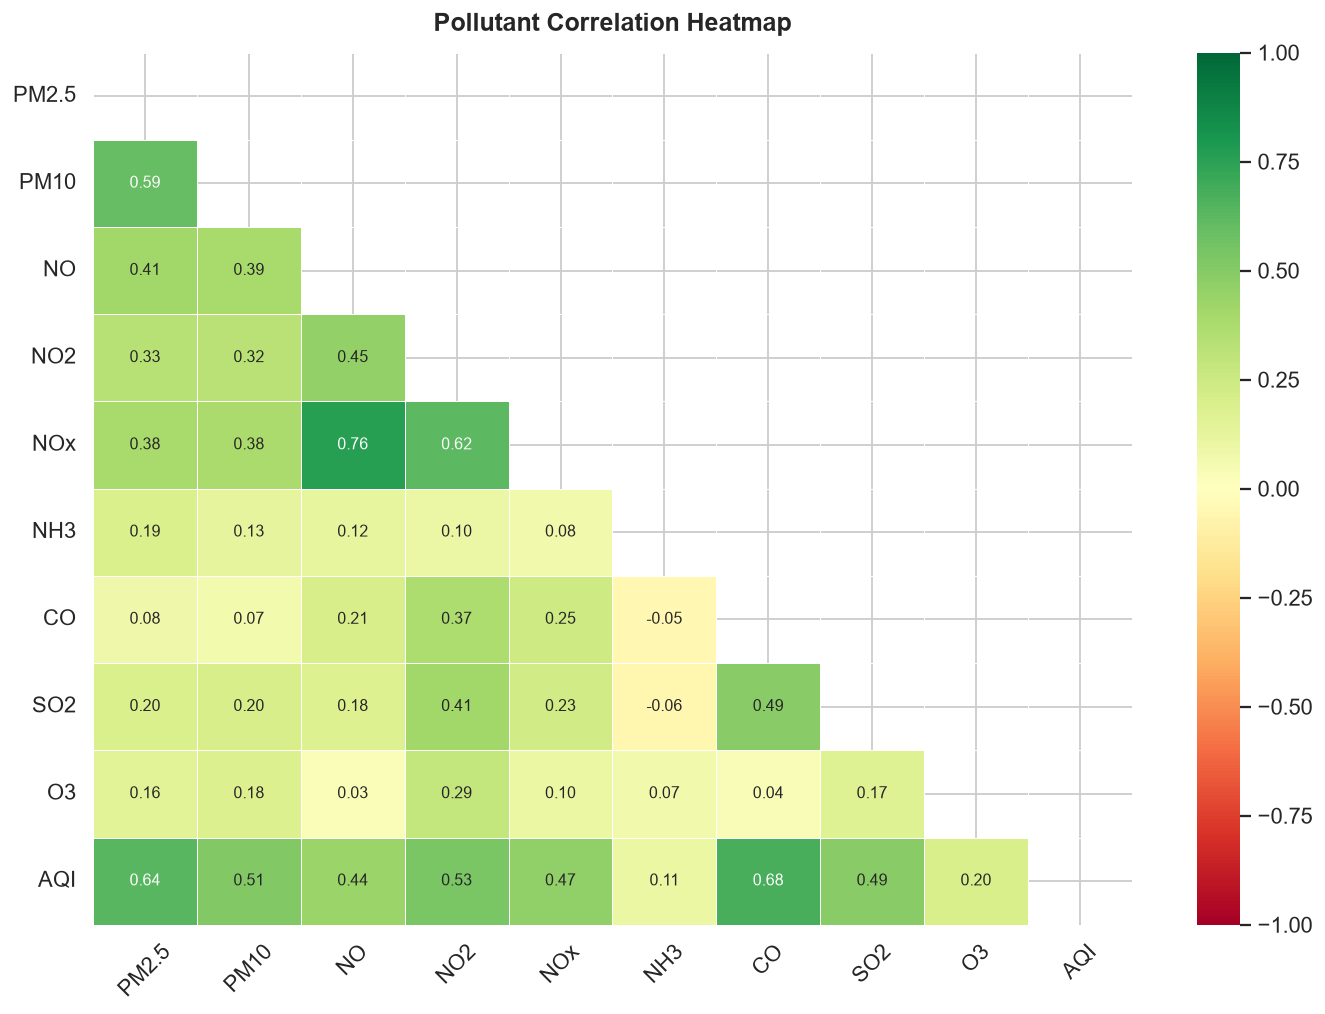

The heatmap describes associations in the imputed dataset.


In [51]:
corr_matrix = df_cleaned[KEY_COLUMNS].corr()
mask        = np.triu(np.ones_like(corr_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdYlGn',
            vmin=-1, vmax=1, linewidths=0.5, ax=ax, annot_kws={'size': 9})
ax.set_title('Pollutant Correlation Heatmap', fontsize=14, fontweight='bold', pad=12)
ax.tick_params(axis='x', rotation=45)
ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'pollutant_correlation_heatmap.png'))
plt.show()

print('The heatmap describes associations in the imputed dataset.')

## Particulate matter scatter plot

A scatter plot shows the paired distribution. PM10 is on the x-axis, PM2.5 on the y-axis and color encodes reported AQI. Points above the equality line warrant a data quality check.

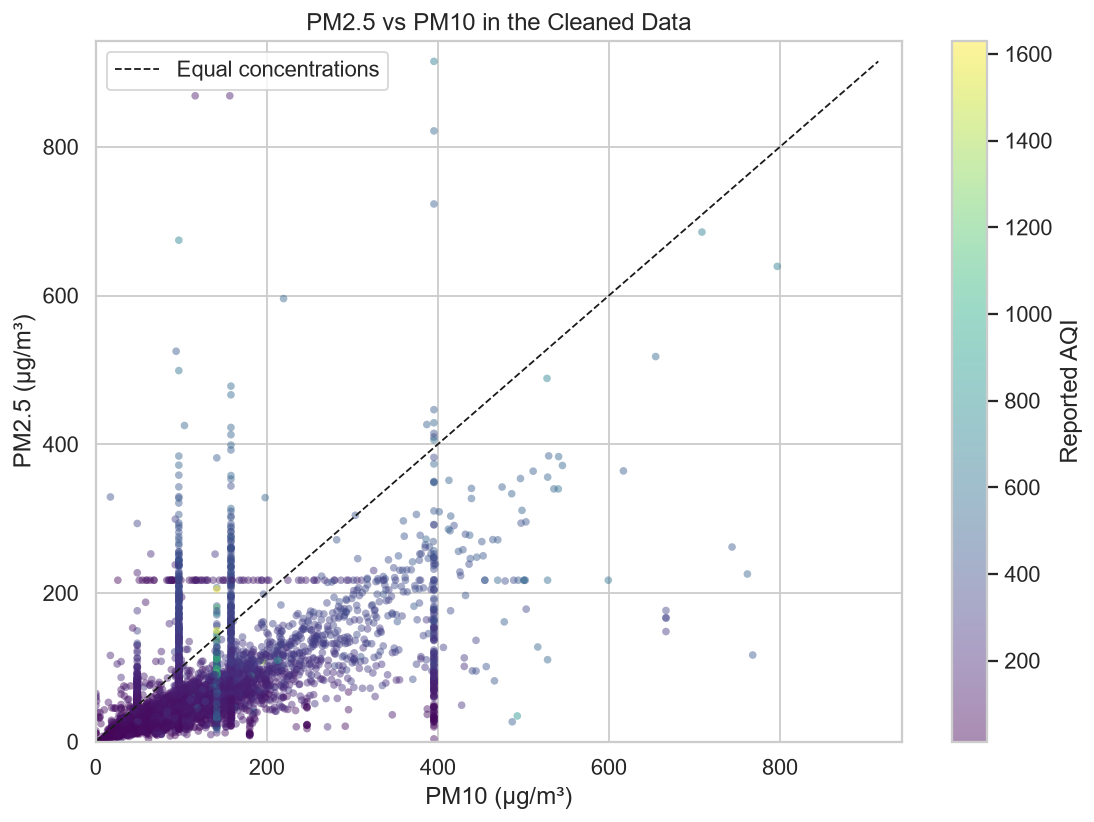

Points above the line have PM2.5 greater than PM10.


In [52]:
sample = df_cleaned.sample(n=min(6000, len(df_cleaned)), random_state=42)

fig, ax = plt.subplots(figsize=(10, 7))
points = ax.scatter(sample["PM10"], sample["PM2.5"], c=sample["AQI"],
                    cmap="viridis", alpha=0.45, s=18, edgecolors="none")
upper = sample[["PM10", "PM2.5"]].max().max()
ax.plot([0, upper], [0, upper], "k--", linewidth=1, label="Equal concentrations")
fig.colorbar(points, ax=ax, label="Reported AQI")
ax.set(title="PM2.5 vs PM10 in the Cleaned Data",
       xlabel="PM10 (µg/m³)", ylabel="PM2.5 (µg/m³)", xlim=(0, upper * 1.03), ylim=(0, upper * 1.03))
ax.legend()
fig.savefig(GRAPH_DIR / "pm25_pm10_scatter.png")
plt.show()

print("Points above the line have PM2.5 greater than PM10.")

**Statistical scope.** The results describe associations. Ordinary independent-row significance tests would ignore repeated observations within cities and dependence across consecutive days. A model-specific diagnostic such as VIF would require a specified model. The observed NO–NOx association already indicates potential overlap.

# 12 Data Visualizations

These charts complete the city and time comparisons. The distributions are shown in Section 7 and the correlation heatmap and particulate scatter plot in Section 11.

## Highest city means

A horizontal bar chart ranks city means. The x-axis is mean AQI and the y-axis lists cities. Ahmedabad leads the pooled ranking, and unusually high readings affect its mean.

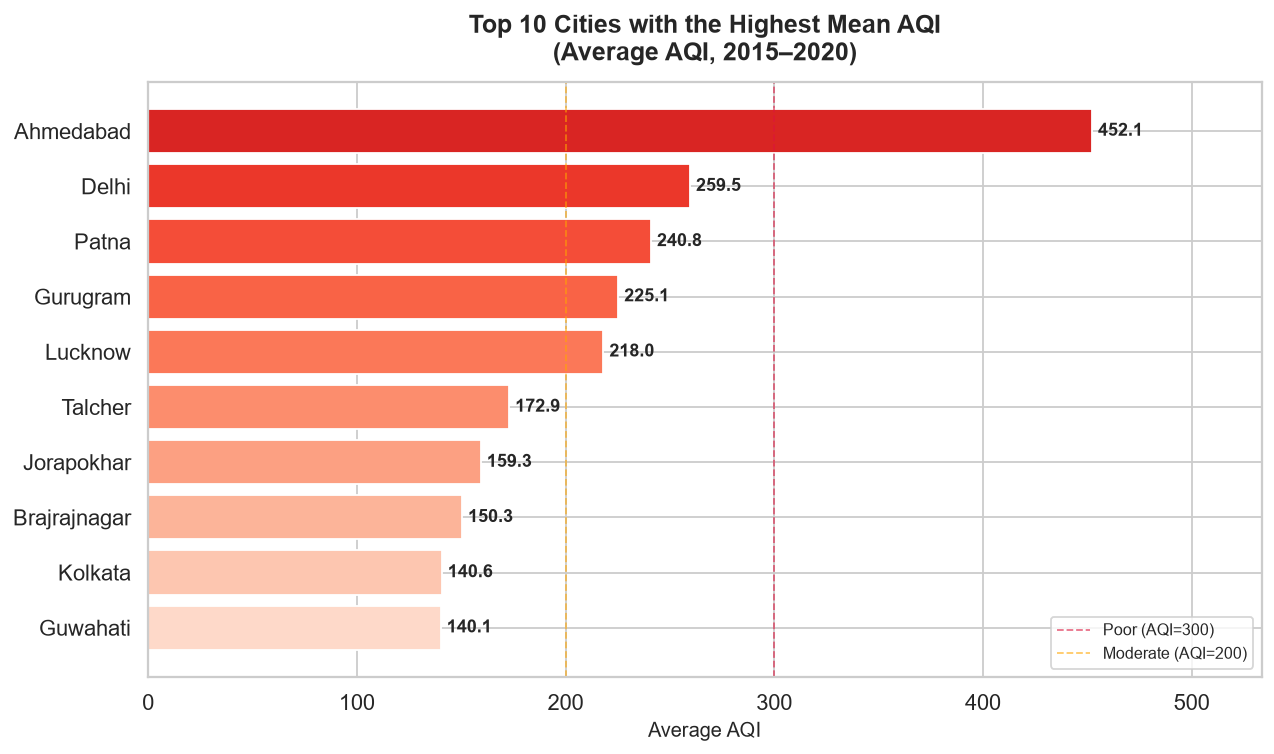

Most polluted: Ahmedabad (avg AQI 452.1)


In [53]:
city_avg = df_cleaned.groupby('City')['AQI'].mean().sort_values(ascending=False).round(1)
top10    = city_avg.head(10)

fig, ax = plt.subplots(figsize=(10, 6))
colors = plt.cm.Reds_r(np.linspace(0.3, 0.85, len(top10)))
bars   = ax.barh(top10.index[::-1], top10.values[::-1], color=colors[::-1], edgecolor='white')

for bar, val in zip(bars, top10.values[::-1]):
    ax.text(bar.get_width() + 3, bar.get_y() + bar.get_height()/2,
            f'{val}', va='center', fontsize=10, fontweight='bold')

ax.set_title('Top 10 Cities with the Highest Mean AQI\n(Average AQI, 2015–2020)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Average AQI', fontsize=11)
ax.set_xlim(0, top10.max() * 1.18)
ax.axvline(300, color='crimson', linestyle='--', linewidth=1, alpha=0.6, label='Poor (AQI=300)')
ax.axvline(200, color='orange',  linestyle='--', linewidth=1, alpha=0.6, label='Moderate (AQI=200)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'top_polluted_cities.png'))
plt.show()

print(f'Most polluted: {city_avg.index[0]} (avg AQI {city_avg.iloc[0]})')

## Lowest city means

A horizontal bar chart makes small city means easy to compare. The x-axis is mean AQI and the y-axis lists cities. Aizawl has the lowest observed mean.

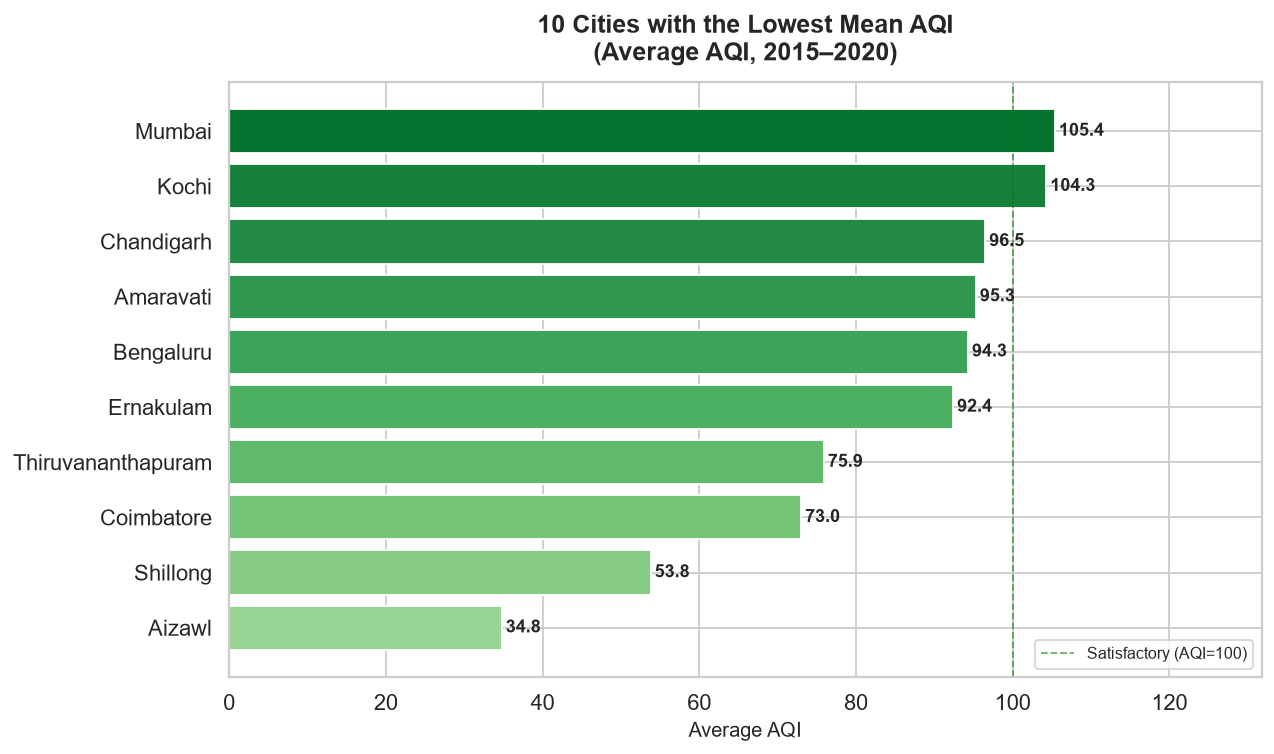

Least polluted: Aizawl (avg AQI 34.8)


In [54]:
bot10 = city_avg.tail(10).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
colors = plt.cm.Greens(np.linspace(0.4, 0.85, len(bot10)))
bars   = ax.barh(bot10.index, bot10.values, color=colors, edgecolor='white')

for bar, val in zip(bars, bot10.values):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{val}', va='center', fontsize=10, fontweight='bold')

ax.set_title('10 Cities with the Lowest Mean AQI\n(Average AQI, 2015–2020)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Average AQI', fontsize=11)
ax.set_xlim(0, bot10.max() * 1.25)
ax.axvline(100, color='green', linestyle='--', linewidth=1, alpha=0.6, label='Satisfactory (AQI=100)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'least_polluted_cities.png'))
plt.show()

print(f'Least polluted: {city_avg.index[-1]} (avg AQI {city_avg.iloc[-1]})')

## Annual AQI trends

A line plot shows annual trajectories. Year is on the x-axis and mean AQI on the y-axis. The pooled series changes city coverage and the comparable series describes Delhi during January to June.

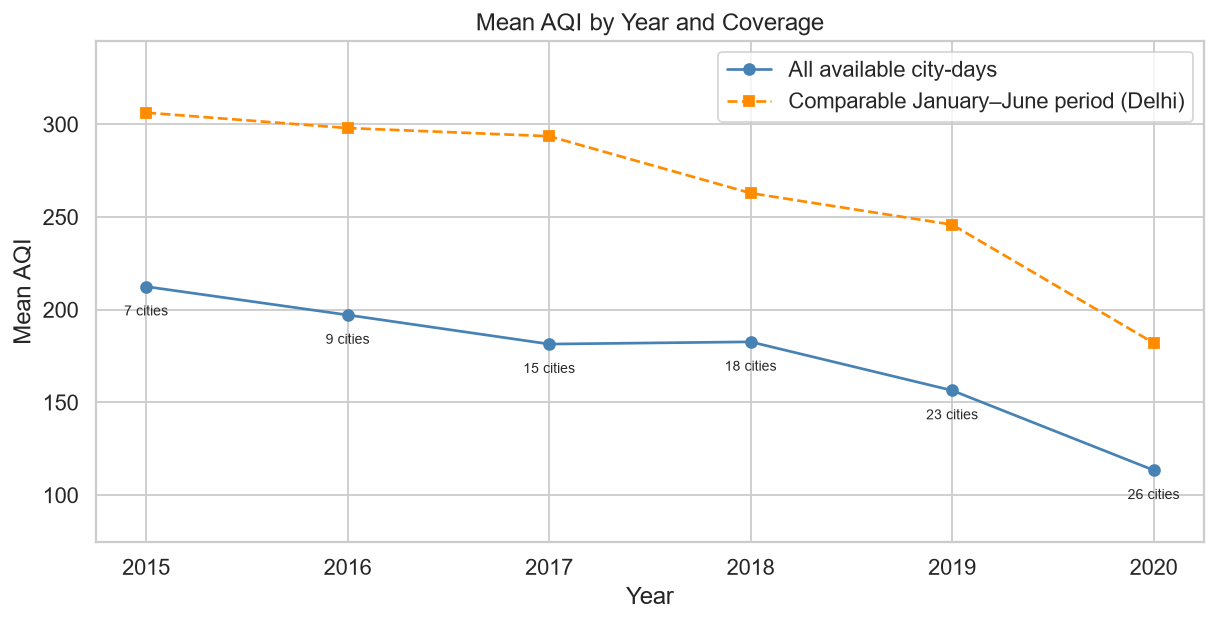

Pooled coverage varies by year. In 2020 the source ends on July 1.


In [55]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(year_summary.index, year_summary["Mean"], marker="o", color="steelblue",
        label="All available city-days")
if panel_cities:
    panel_label = ", ".join(panel_cities) if len(panel_cities) == 1 else f"{len(panel_cities)} cities"
    ax.plot(panel.index, panel["Mean_AQI"], marker="s", color="darkorange", linestyle="--",
            label=f"Comparable January–June period ({panel_label})")
for year, row in year_summary.iterrows():
    ax.annotate(f"{int(row['Cities'])} cities", (year, row["Mean"]), textcoords="offset points",
                xytext=(0, -16), ha="center", fontsize=8)
ax.set(title="Mean AQI by Year and Coverage", xlabel="Year", ylabel="Mean AQI",
       xticks=year_summary.index)
ax.legend()
ax.margins(y=0.2)
fig.savefig(GRAPH_DIR / "yearly_aqi_trend.png")
plt.show()

print("Pooled coverage varies by year. In 2020 the source ends on July 1.")

## Monthly AQI trends

Ordered monthly bars show seasonal differences. The x-axis is calendar month and the y-axis is pooled mean AQI. November is highest and July lowest in the available data.

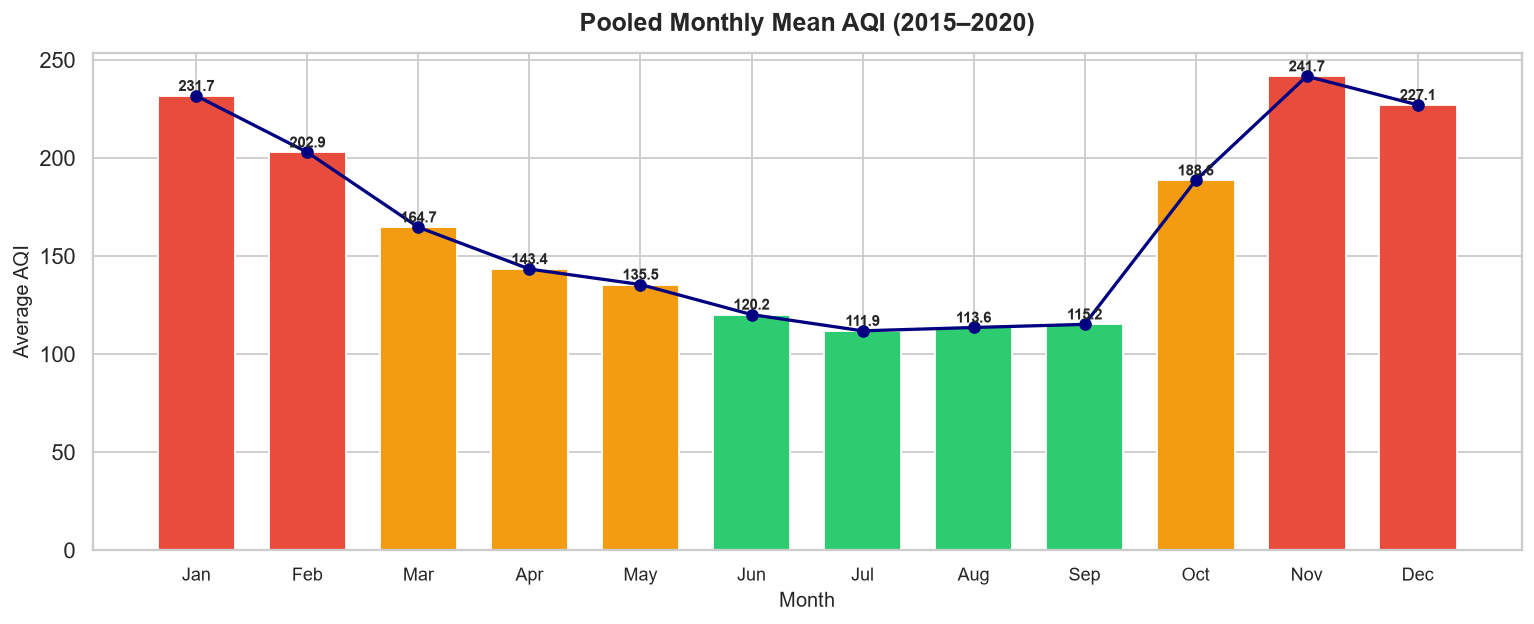

Peak month: November (241.7)
Lowest month: July (111.9)


In [56]:
month_short = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
month_avg   = df_cleaned.groupby('Month')['AQI'].mean().reindex(MONTH_ORDER).round(1)

bar_colors = ['#e74c3c' if v > 200 else '#f39c12' if v > 130 else '#2ecc71'
              for v in month_avg.values]

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(range(1, 13), month_avg.values, color=bar_colors, edgecolor='white', width=0.7)
ax.plot(range(1, 13), month_avg.values, marker='o', color='navy', linewidth=1.8, markersize=6, zorder=3)

for i, val in enumerate(month_avg.values):
    ax.text(i + 1, val + 2.5, f'{val}', ha='center', fontsize=8.5, fontweight='bold')

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_short, fontsize=10)
ax.set_title('Pooled Monthly Mean AQI (2015–2020)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Month', fontsize=11)
ax.set_ylabel('Average AQI', fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'monthly_aqi_trend.png'))
plt.show()

print(f'Peak month: {month_avg.idxmax()} ({month_avg.max():.1f})')
print(f'Lowest month: {month_avg.idxmin()} ({month_avg.min():.1f})')

## Mean concentrations by city

Research question 8 compares mean pollutant concentrations across cities.

Grouped bars compare three particulate or gas measures on a common concentration scale. The x-axis lists cities and the y-axis is mean concentration in µg/m³. The highest city differs across pollutants.

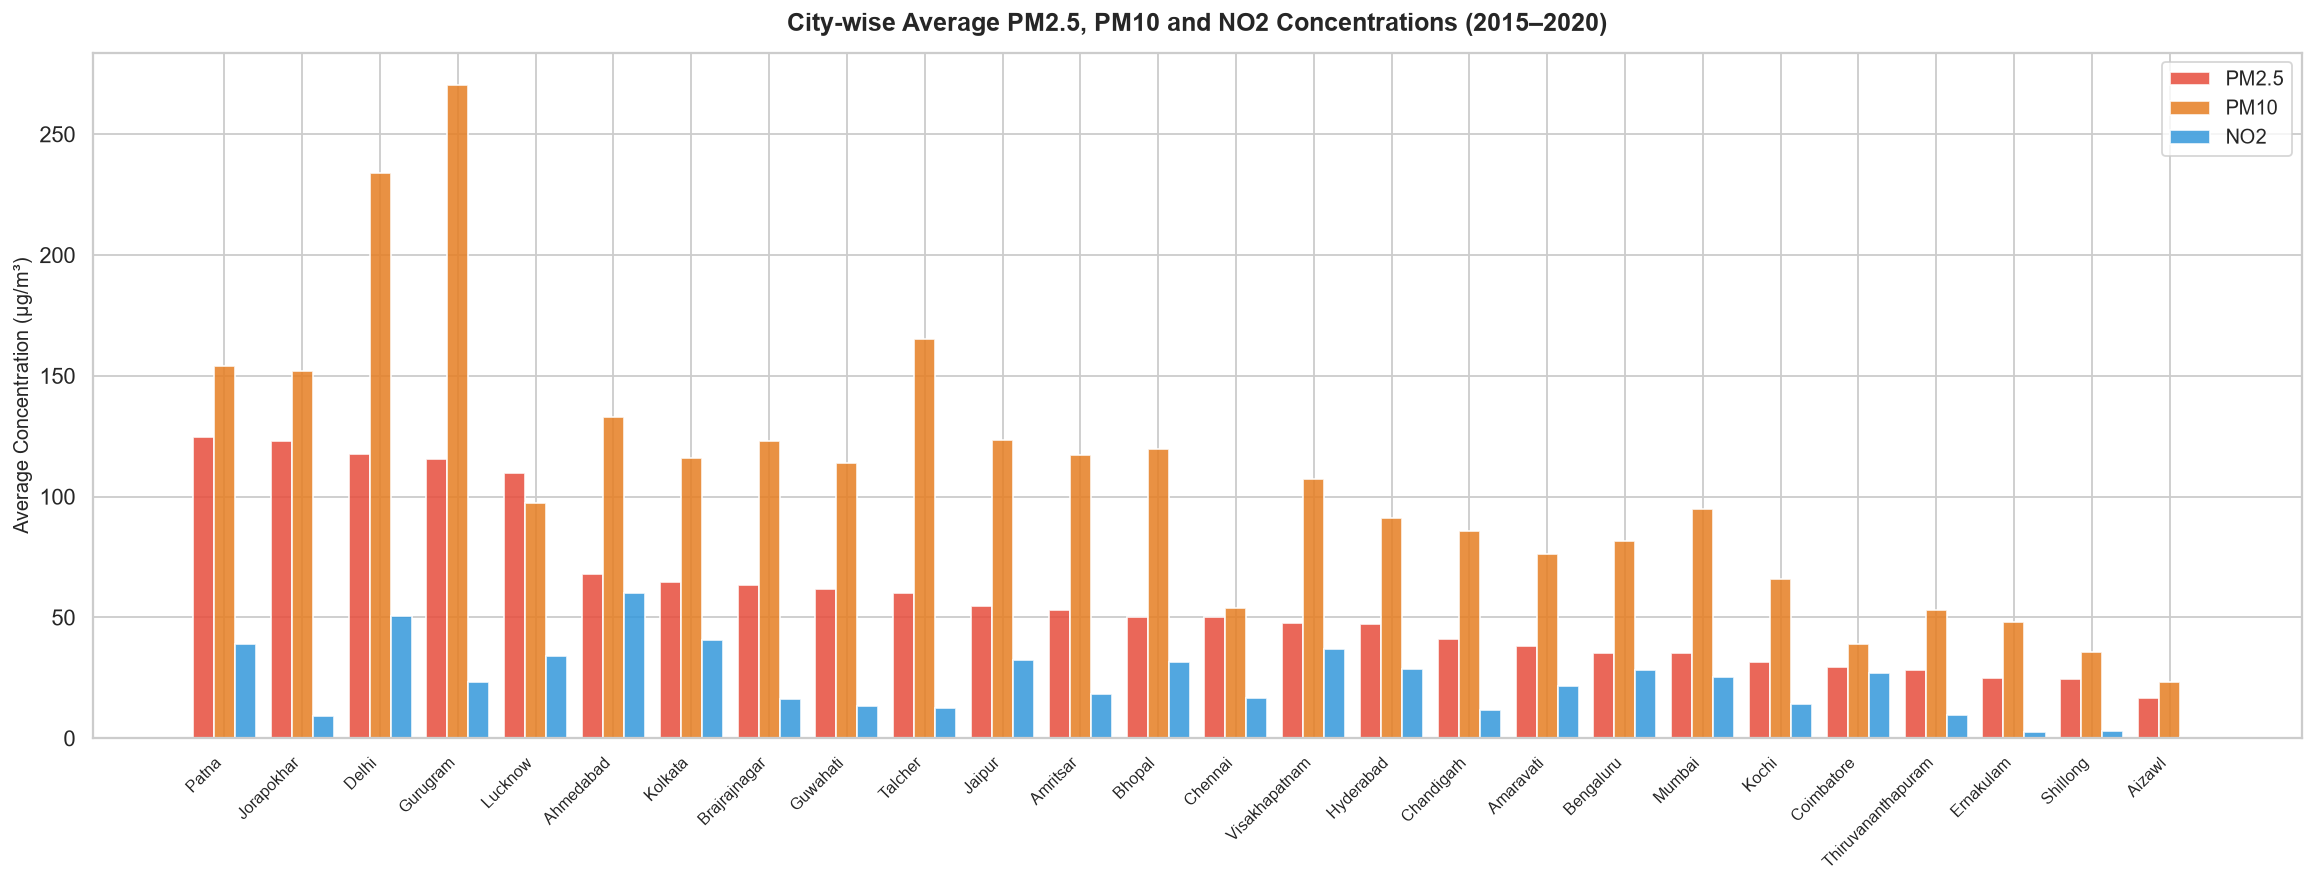

PM2.5        Patna
PM10      Gurugram
NO2      Ahmedabad
Name: City with highest mean concentration, dtype: str

In [57]:
city_poll = df_cleaned.groupby('City')[['PM2.5', 'PM10', 'NO2']].mean().sort_values('PM2.5', ascending=False).round(1)
x     = np.arange(len(city_poll))
width = 0.27

fig, ax = plt.subplots(figsize=(18, 7))
ax.bar(x - width, city_poll['PM2.5'], width, label='PM2.5', color='#e74c3c', alpha=0.85, edgecolor='white')
ax.bar(x,          city_poll['PM10'],  width, label='PM10',  color='#e67e22', alpha=0.85, edgecolor='white')
ax.bar(x + width, city_poll['NO2'],   width, label='NO2',   color='#3498db', alpha=0.85, edgecolor='white')

ax.set_xticks(x)
ax.set_xticklabels(city_poll.index, rotation=45, ha='right', fontsize=9)
ax.set_title('City-wise Average PM2.5, PM10 and NO2 Concentrations (2015–2020)',
             fontsize=14, fontweight='bold', pad=12)
ax.set_ylabel('Average Concentration (µg/m³)', fontsize=11)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'city_pollutant_comparison.png'))
plt.show()

display(city_poll.idxmax().rename("City with highest mean concentration"))

## AQI category mix by city

A 100% stacked bar chart compares composition. The x-axis shows the share of reported days and the y-axis lists eligible 2019 cities. Ahmedabad has the largest Poor-or-worse share.

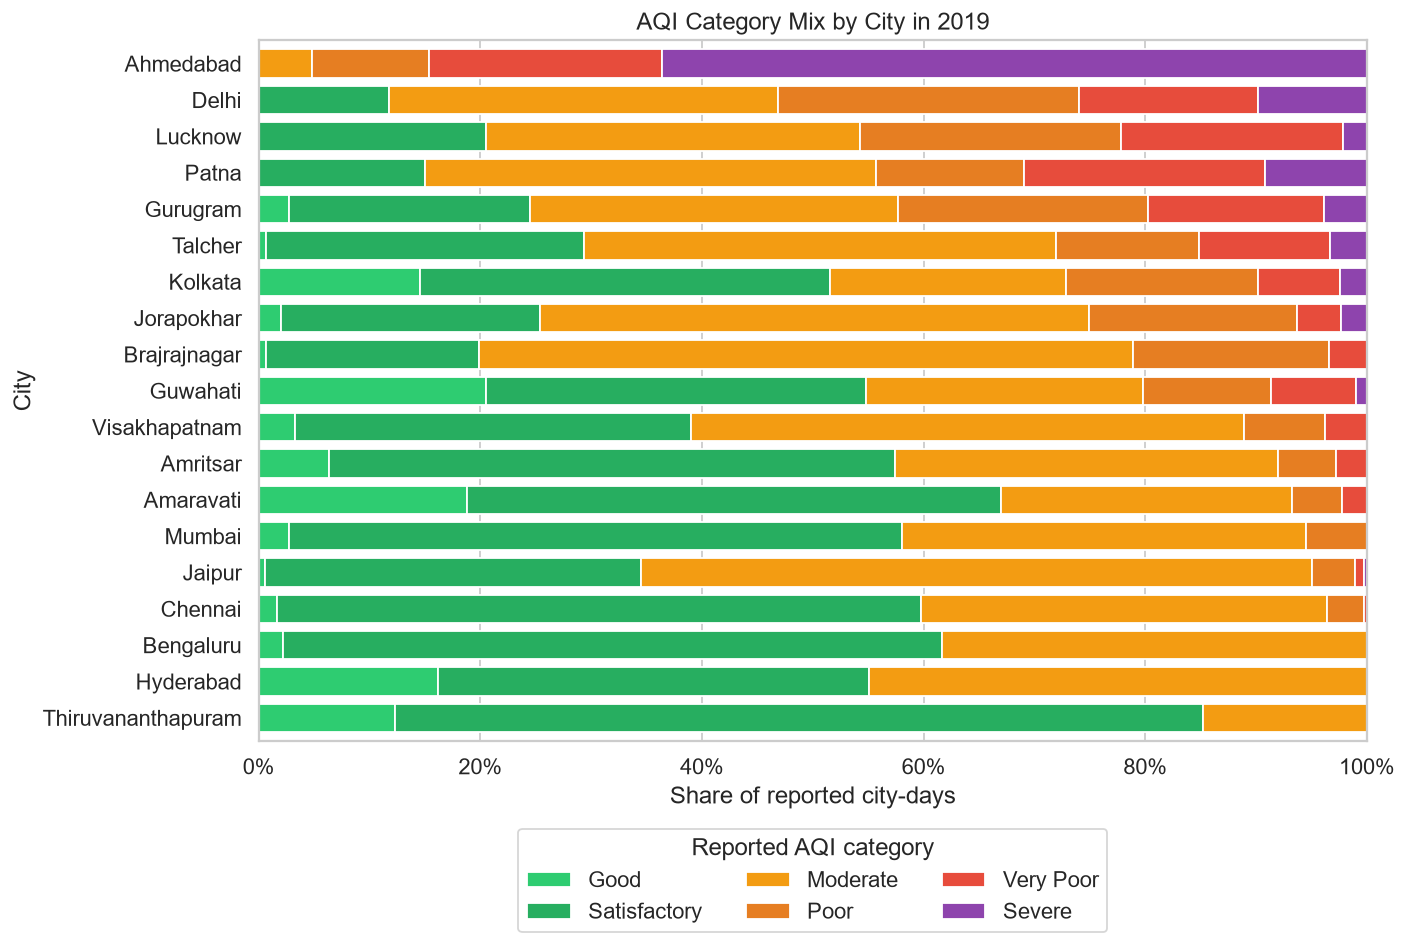

In [58]:
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(11, 7))
category_profile[AQI_CATEGORIES].iloc[::-1].plot.barh(
    stacked=True, ax=ax, color=cat_colors, width=0.78
)
ax.set(xlim=(0, 100), xlabel="Share of reported city-days", ylabel="City",
       title="AQI Category Mix by City in 2019")
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.legend(title="Reported AQI category", ncol=3, loc="upper center",
          bbox_to_anchor=(0.5, -0.11))
fig.savefig(GRAPH_DIR / "city_aqi_category_profile_2019.png")
plt.show()

# 13 Important Findings

1. **Typical AQI was below the mean.** The median was 118 and the mean was 166.5. The histogram shows high values pulling the mean upward.
2. **Moderate was the largest category.** It made up 35.5% of reported city-days. Poor, Very Poor and Severe accounted for 26.0% combined. See the category bars.
3. **City rankings depend on the reported sample.** Ahmedabad averaged 452.1 and Aizawl 34.8. Ahmedabad remained first below or at AQI 500, but its mean fell to 291.7. See the city charts and sensitivity table.
4. **City category profiles reveal frequency differences.** In 2019, 95.17% of Ahmedabad's 352 available days and 53.15% of Delhi's 365 days were Poor or worse. See the stacked bars. Bengaluru and Hyderabad each had zero Poor or worse days among their 365 reported days.
5. **The annual denominator changed.** Coverage grew from seven cities to 26, and 2020 ends on July 1. The comparable January–June series shows Delhi alone going from 306.3 to 182.1. See the yearly chart.
6. **Pooled AQI differed by month.** November (241.7) exceeded July (111.9). Coverage varies across months. See the monthly chart.
7. **Particulate associations depended on measurement availability and filling.** PM10–AQI Pearson r was 0.803 on 17,764 measured pairs and 0.514 in the filled dataset. PM2.5–PM10 moved from 0.853 to 0.594. See the selected-pair table and scatter plot.
8. **Strong associations coexist with weak ones.** NO–NOx measured Pearson r was 0.801, while NH3–SO2 showed −0.028. The selected-pair table supports potential feature redundancy for the former and little linear evidence for the latter.

## Limitations

- City coverage and the number of reported days vary by year. The 2020 source ends on July 1. The comparable-period check represents only the cities that meet the coverage threshold.
- Imputation repeats or estimates missing readings. The measured-pair comparison shows how sensitive the PM2.5–PM10 correlation is to the analyzed sample and gap filling.
- AQI values above 500 and cases of PM10 below PM2.5 need source-level validation. Station counts and locations are unavailable in the city-day file.
- The records reflect monitored city-days. The analysis does not estimate population exposure or isolate the effects of weather, lockdowns, or emissions policy.

# 14 Final Conclusions

The observed city-days show substantial differences in reported AQI between cities and months. The January–June coverage check supports a more specific finding for Delhi, while the sensitivity results show how extreme values and imputation affect estimates. Together these results show where the dataset can inform an SDG 11 air-quality discussion and where more complete monitoring data would be needed.